# 02 - Data Visualization

## Objectives

* Answer **business requirement 1**: visually differentiate a healthy cherry leaf from one with powdery mildew.

## Inputs

* `inputs/cherry_leaves_dataset/cherry-leaves/train`
* `inputs/cherry_leaves_dataset/cherry-leaves/validation`
* `inputs/cherry_leaves_dataset/cherry-leaves/test`

## Outputs

* Image shape (`image_shape.pkl`) and image dimension plot
* Average and variability image for each label
* Difference between the average healthy and average mildew leaf
* Image montage for each label
* Number of images per set and label (plot and CSV)
* Brightness comparison with a statistical test (hypothesis 2)

All outputs are saved in `outputs/v1/` so they can be shown on the dashboard.

## Additional comments

* `v1` is the project version folder: a new version of the outputs would go into `outputs/v2/`.

---

# Change working directory

The notebooks live in `jupyter_notebooks/`, but all paths in this project are relative to the repository root, so we move one folder up.

In [1]:
import os

current_dir = os.getcwd()
if os.path.basename(current_dir) == 'jupyter_notebooks':
    os.chdir(os.path.dirname(current_dir))
print('Working directory:', os.getcwd())

Working directory: /Users/mlamleli/Documents/Mlamleli Projects/mildew-detector


---

# Imports and paths

In [2]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

sns.set_style('white')

my_data_dir = os.path.join('inputs', 'cherry_leaves_dataset', 'cherry-leaves')
train_path = os.path.join(my_data_dir, 'train')
labels = sorted(os.listdir(train_path))
print('Labels:', labels)

version = 'v1'
file_path = os.path.join('outputs', version)
os.makedirs(file_path, exist_ok=True)
print('Outputs will be saved to', file_path)

Matplotlib is building the font cache; this may take a moment.


Labels: ['healthy', 'powdery_mildew']
Outputs will be saved to outputs/v1


---

# Set the image shape

We check the height and width of the training images. The model needs every image to be the same size. The original images are 256 x 256 pixels; we resize them to **128 x 128** to make training faster and the saved model smaller, while keeping the white mildew patches visible.

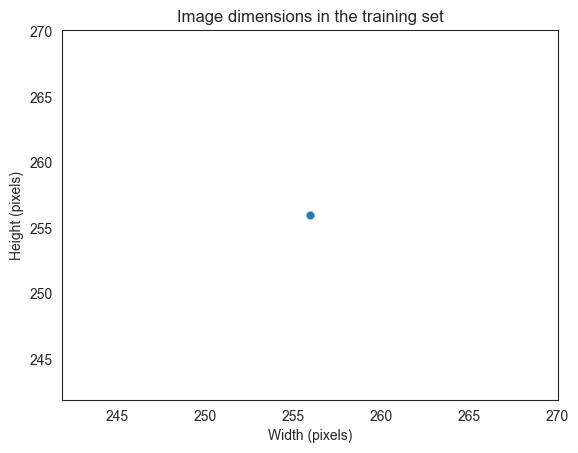

Average width: 256 px, average height: 256 px


In [3]:
dim1, dim2 = [], []
for label in labels:
    for image_filename in os.listdir(os.path.join(train_path, label)):
        with Image.open(os.path.join(train_path, label, image_filename)) as img:
            width, height = img.size
        dim1.append(height)
        dim2.append(width)

fig, axes = plt.subplots()
sns.scatterplot(x=dim2, y=dim1, alpha=0.2)
axes.set_xlabel('Width (pixels)')
axes.set_ylabel('Height (pixels)')
axes.set_title('Image dimensions in the training set')
plt.show()

print(f'Average width: {int(np.mean(dim2))} px, average height: {int(np.mean(dim1))} px')

In [4]:
image_shape = (128, 128, 3)
joblib.dump(value=image_shape, filename=os.path.join(file_path, 'image_shape.pkl'))
print('Image shape used by the model:', image_shape)

Image shape used by the model: (128, 128, 3)


---

# Load images into memory as arrays

We load a sample of each label from the training set, resize them to the image shape and scale the pixel values to 0-1.

In [5]:
def load_image_as_array(my_data_dir, new_size=(128, 128), n_images_per_label=300):
    """Return images as a numpy array (X) and their labels (y)."""
    X, y = [], []
    for label in sorted(os.listdir(my_data_dir)):
        files = sorted(os.listdir(os.path.join(my_data_dir, label)))[:n_images_per_label]
        for image_filename in files:
            img = Image.open(os.path.join(my_data_dir, label, image_filename))
            img = img.convert('RGB').resize(new_size)
            X.append(np.array(img) / 255.0)
            y.append(label)
    return np.array(X), np.array(y)


X, y = load_image_as_array(train_path, new_size=image_shape[:2])
print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (600, 128, 128, 3) | y shape: (600,)


---

# Average and variability image per label

* The **average image** shows what a 'typical' leaf of each label looks like.
* The **variability image** (standard deviation) shows where the images differ most from each other.

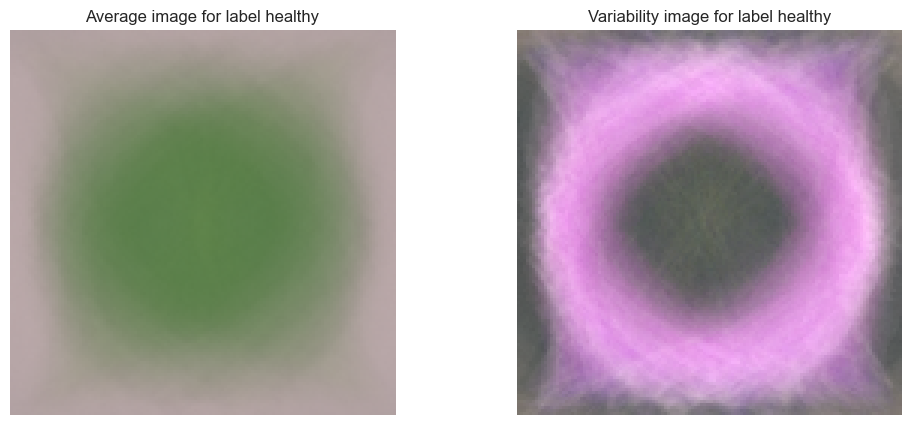

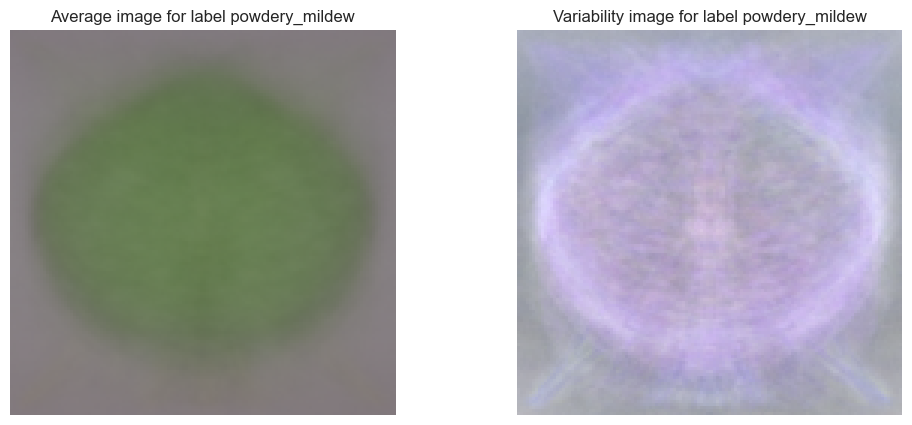

In [6]:
def plot_average_variability_per_label(X, y, figsize=(12, 5), save_image=True):
    """Plot and save the mean and standard deviation image for each label."""
    for label_to_display in np.unique(y):
        boolean_mask = y == label_to_display
        avg_img = np.mean(X[boolean_mask], axis=0)
        std_img = np.std(X[boolean_mask], axis=0)

        fig, axes = plt.subplots(nrows=1, ncols=2, figsize=figsize)
        axes[0].set_title(f'Average image for label {label_to_display}')
        axes[0].imshow(avg_img)
        axes[1].set_title(f'Variability image for label {label_to_display}')
        axes[1].imshow(std_img / std_img.max())
        for ax in axes:
            ax.axis('off')

        if save_image:
            plt.savefig(os.path.join(file_path, f'avg_var_{label_to_display}.png'),
                        bbox_inches='tight', dpi=150)
        plt.show()


plot_average_variability_per_label(X, y)

---

# Difference between the average images

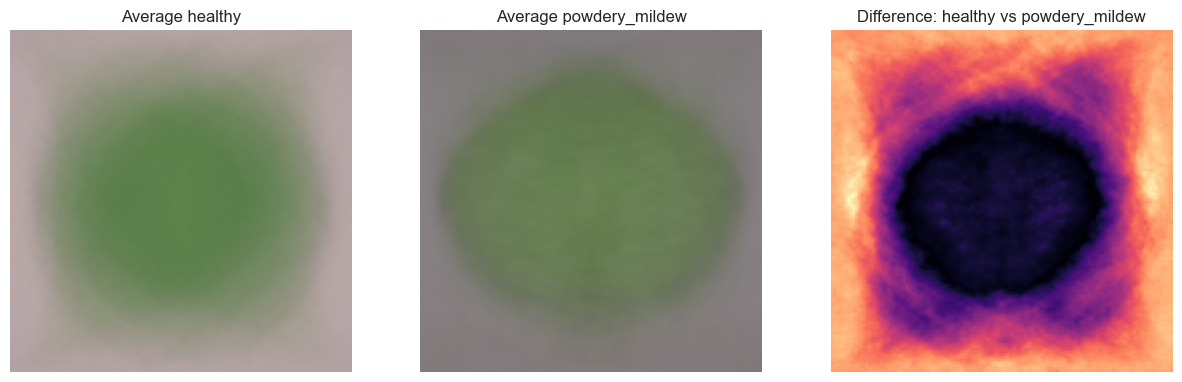

In [7]:
def subset_image_label(X, y, label_to_display):
    return X[y == label_to_display]


def diff_bet_avg_image_labels(X, y, label_1, label_2, figsize=(15, 5), save_image=True):
    """Plot the average image of two labels and the difference between them."""
    label1_avg = np.mean(subset_image_label(X, y, label_1), axis=0)
    label2_avg = np.mean(subset_image_label(X, y, label_2), axis=0)
    difference_mean = label1_avg - label2_avg

    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=figsize)
    axes[0].imshow(label1_avg)
    axes[0].set_title(f'Average {label_1}')
    axes[1].imshow(label2_avg)
    axes[1].set_title(f'Average {label_2}')
    # Show the size of the difference per pixel (brighter = bigger difference)
    diff_display = np.abs(difference_mean).mean(axis=2)
    axes[2].imshow(diff_display, cmap='magma')
    axes[2].set_title(f'Difference: {label_1} vs {label_2}')
    for ax in axes:
        ax.axis('off')

    if save_image:
        plt.savefig(os.path.join(file_path, 'avg_diff.png'), bbox_inches='tight', dpi=150)
    plt.show()


diff_bet_avg_image_labels(X, y, label_1='healthy', label_2='powdery_mildew')

---

# Image montage

A montage shows a grid of random real images for each label, so the user can see the difference with their own eyes.

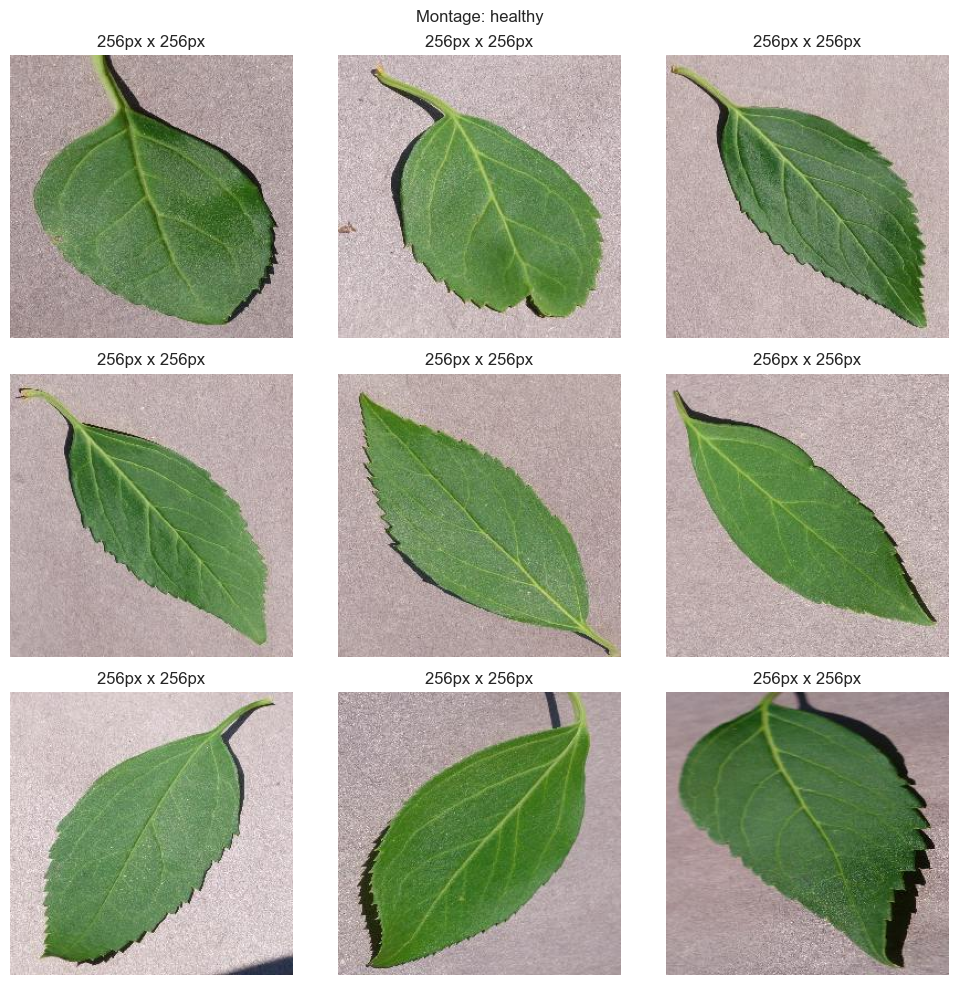

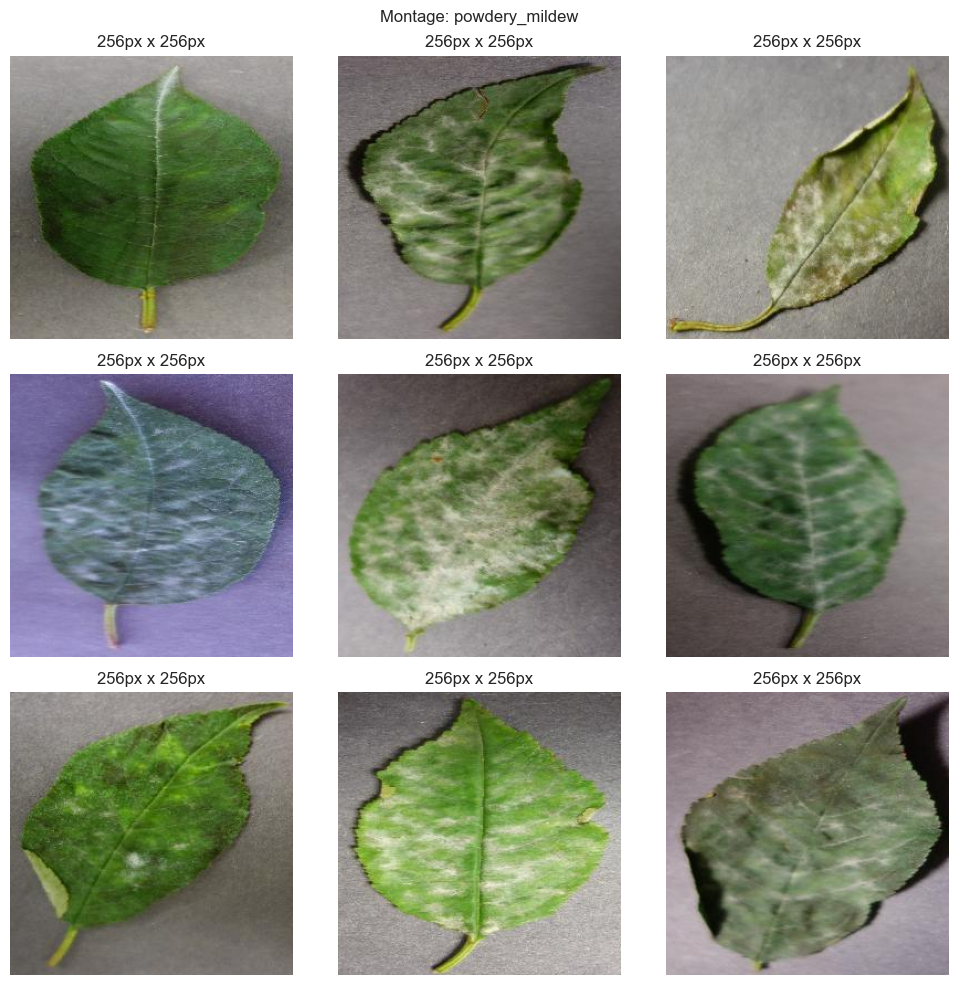

In [8]:
import random


def image_montage(dir_path, label_to_display, nrows=3, ncols=3,
                  figsize=(10, 10), save_image=True, seed=7):
    """Plot and save a grid of random images for one label."""
    images_list = sorted(os.listdir(os.path.join(dir_path, label_to_display)))
    n_images = min(nrows * ncols, len(images_list))
    random.seed(seed)
    img_idx = random.sample(images_list, n_images)

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=figsize)
    for ax, image_name in zip(axes.flatten(), img_idx):
        img = Image.open(os.path.join(dir_path, label_to_display, image_name))
        ax.imshow(img)
        ax.set_title(f'{img.size[0]}px x {img.size[1]}px')
    for ax in axes.flatten():
        ax.axis('off')
    plt.suptitle(f'Montage: {label_to_display}')
    plt.tight_layout()

    if save_image:
        plt.savefig(os.path.join(file_path, f'montage_{label_to_display}.png'),
                    bbox_inches='tight', dpi=100)
    plt.show()


for label in labels:
    image_montage(train_path, label)

---

# Number of images in train, validation and test sets

          Set           Label  Frequency
0       train         healthy       1472
1       train  powdery_mildew       1472
2  validation         healthy        210
3  validation  powdery_mildew        210
4        test         healthy        422
5        test  powdery_mildew        422


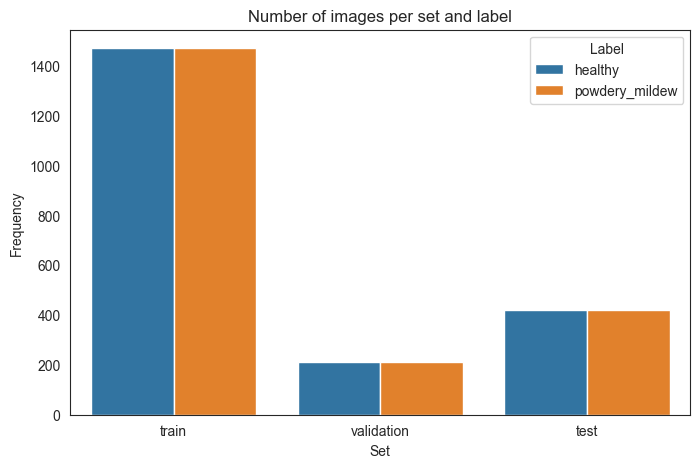

In [9]:
rows = []
for set_name in ['train', 'validation', 'test']:
    for label in labels:
        n = len(os.listdir(os.path.join(my_data_dir, set_name, label)))
        rows.append({'Set': set_name, 'Label': label, 'Frequency': n})
df_freq = pd.DataFrame(rows)
df_freq.to_csv(os.path.join(file_path, 'labels_distribution.csv'), index=False)
print(df_freq)

plt.figure(figsize=(8, 5))
sns.barplot(data=df_freq, x='Set', y='Frequency', hue='Label')
plt.title('Number of images per set and label')
plt.savefig(os.path.join(file_path, 'labels_distribution.png'), bbox_inches='tight', dpi=150)
plt.show()

---

# Hypothesis 2: mildew leaves are brighter

Powdery mildew appears as **white, powdery patches**. If that is true, leaves with mildew should on average be brighter than healthy leaves.

* We compute the mean brightness (0 = black, 1 = white) of every sampled image.
* We compare the two groups with a **Mann-Whitney U test** (it does not assume the data is normally distributed).
* We reject the null hypothesis (no difference) if **p < 0.05**.

{
  "healthy_mean_brightness": 0.5386,
  "mildew_mean_brightness": 0.4478,
  "u_statistic": 16296.0,
  "p_value": 1.19657886974328e-41,
  "significant": true
}


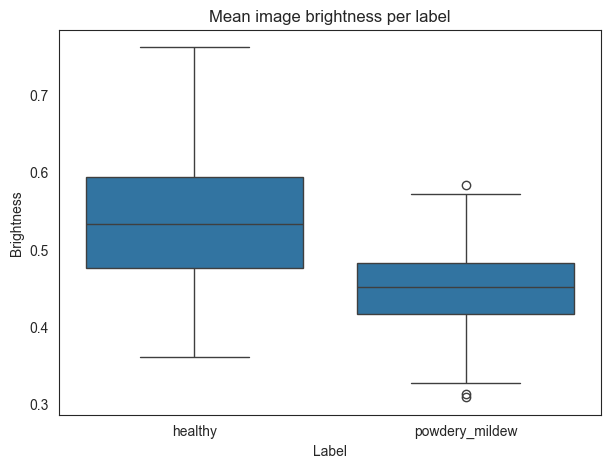

In [10]:
from scipy import stats
import json

brightness = X.mean(axis=(1, 2, 3))
df_bright = pd.DataFrame({'Label': y, 'Brightness': brightness})

healthy_b = df_bright.query("Label == 'healthy'")['Brightness']
mildew_b = df_bright.query("Label == 'powdery_mildew'")['Brightness']
u_stat, p_value = stats.mannwhitneyu(mildew_b, healthy_b, alternative='two-sided')

result = {
    'healthy_mean_brightness': round(float(healthy_b.mean()), 4),
    'mildew_mean_brightness': round(float(mildew_b.mean()), 4),
    'u_statistic': float(u_stat),
    'p_value': float(p_value),
    'significant': bool(p_value < 0.05),
}
with open(os.path.join(file_path, 'brightness_test.json'), 'w') as f:
    json.dump(result, f, indent=2)
print(json.dumps(result, indent=2))

plt.figure(figsize=(7, 5))
sns.boxplot(data=df_bright, x='Label', y='Brightness')
plt.title('Mean image brightness per label')
plt.savefig(os.path.join(file_path, 'brightness_boxplot.png'), bbox_inches='tight', dpi=150)
plt.show()

**Interpretation:** *(write this after running - check the printed numbers)* If `significant` is `True` and the mildew mean is higher, the data supports hypothesis 2: mildew leaves are measurably brighter, which matches the white patches. If not, say so honestly - brightness alone is then not enough to tell the classes apart, which is why we need a model that learns shapes and textures (notebook 03).

---

# Conclusions and next steps

* *(Update after running)* The average healthy leaf is an even green; the average mildew leaf shows lighter, whiter areas. The difference image highlights where they differ.
* The montages show the white powdery patches clearly on infected leaves.
* Train, validation and test sets are balanced between the two labels.
* **Next:** `03_Modelling_and_Evaluation.ipynb` - build the model for business requirement 2.